Plotting the Wu spectra (prereduced)

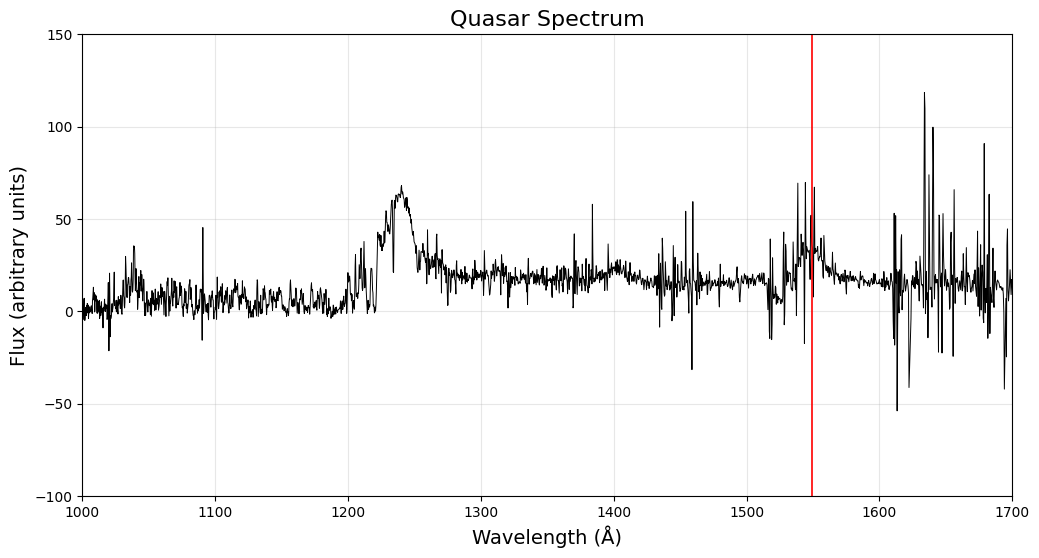

In [16]:
from astropy.io import fits
import matplotlib.pyplot as plt

file = "op-4490-55629-0074"

# Path to your FITS file
file_path = f"/Users/nayera/PyQSOFit/DR16_specs/{file}.fits"

# Open the FITS file
hdul = fits.open(file_path)

# Work with HDU 3 (spectrum data)
data_spec = hdul[3].data

# Get redshift from HDU 1
z = hdul[1].data['Z_FIT'][0]

# Observed wavelength and flux
wavelength_obs = data_spec['wave_prereduced']
flux = data_spec['flux_prereduced']

# Convert to rest-frame
wavelength_rest = wavelength_obs / (1 + z)

# Plot the spectrum
plt.figure(figsize=(12,6))
plt.plot(wavelength, flux, color="black", lw=0.7)
plt.xlabel("Wavelength (Å)", fontsize=14)
plt.axvline(1549, color="red", lw=1.2, label="C IV (1549 Å)")
plt.ylabel("Flux (arbitrary units)", fontsize=14)
plt.title("Quasar Spectrum", fontsize=16)
plt.xlim(1000, 1700)   # set wavelength bounds
plt.ylim(-100, 150)
plt.grid(alpha=0.3)
plt.show()

# Close the FITS file
hdul.close()


In [2]:
print(hdul[1].columns.names)

['RA', 'DEC', 'PLATE', 'MJD', 'FIBERID', 'ObjID', 'Z_FIT', 'SNR_conti', 'EBV', 'MC_trails', 'conti_chi2', 'conti_rchi2', 'conti_dof', 'conti_npix', 'Fe_uv_norm', 'Fe_uv_norm_err', 'Fe_uv_norm_err2', 'Fe_uv_FWHM', 'Fe_uv_FWHM_err', 'Fe_uv_FWHM_err2', 'Fe_uv_shift', 'Fe_uv_shift_err', 'Fe_uv_shift_err2', 'Fe_op_norm', 'Fe_op_norm_err', 'Fe_op_norm_err2', 'Fe_op_FWHM', 'Fe_op_FWHM_err', 'Fe_op_FWHM_err2', 'Fe_op_shift', 'Fe_op_shift_err', 'Fe_op_shift_err2', 'Fe_uv_EW', 'Fe_op_EW', 'Fe_uv_EW_err', 'Fe_op_EW_err', 'PL_norm', 'PL_norm_err', 'PL_norm_err2', 'PL_slope', 'PL_slope_err', 'PL_slope_err2', 'Blamer_norm', 'Blamer_norm_err', 'Blamer_norm_err2', 'Balmer_Te', 'Balmer_Te_err', 'Balmer_Te_err2', 'Balmer_Tau', 'Balmer_Tau_err', 'Balmer_Tau_err2', 'POLY_a', 'POLY_a_err', 'POLY_a_err2', 'POLY_b', 'POLY_b_err', 'POLY_b_err2', 'POLY_c', 'POLY_c_err', 'POLY_c_err2', 'L1350', 'L1350_err', 'L1350_err2', 'L1700', 'L1700_err', 'L1700_err2', 'L3000', 'L3000_err', 'L3000_err2', 'L5100', 'L5100_err

In [3]:
print(hdul[3].columns.names)

['wave_prereduced', 'flux_prereduced', 'err_prereduced', 'wave_conti', 'flux_conti', 'err_conti', 'wave_line', 'flux_line', 'err_line', 'wave_line_abs', 'flux_line_abs', 'err_line_abs']


Plotting the Wu spectra with their continuum and line fits

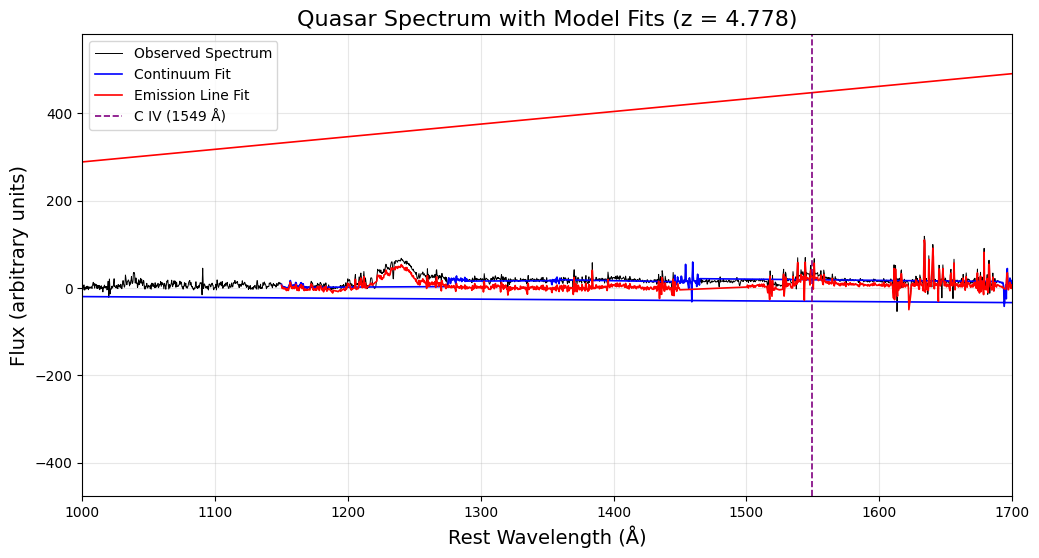

In [20]:
from astropy.io import fits
import matplotlib.pyplot as plt

# Path setup
file = "op-4490-55629-0074"
file_path = f"/Users/nayera/PyQSOFit/DR16_specs/{file}.fits"

# Open file
hdul = fits.open(file_path)

# Data
data_spec = hdul[3].data
z = hdul[1].data['Z_FIT'][0]  # redshift

# Observed data
wave_obs = data_spec['wave_prereduced']
flux_obs = data_spec['flux_prereduced']

# Continuum + lines
wave_conti = data_spec['wave_conti']
flux_conti = data_spec['flux_conti']
wave_line = data_spec['wave_line']
flux_line = data_spec['flux_line']

# Rest-frame conversion
wave_rest = wave_obs # / (1 + z)
wave_conti_rest = wave_conti #/ (1 + z)
wave_line_rest = wave_line #/ (1 + z)

# Plot
plt.figure(figsize=(12,6))
plt.plot(wave_rest, flux_obs, color="black", lw=0.7, label="Observed Spectrum")
plt.plot(wave_conti_rest, flux_conti, color="blue", lw=1.2, label="Continuum Fit")
plt.plot(wave_line_rest, flux_line, color="red", lw=1.2, label="Emission Line Fit")

# Mark C IV
plt.axvline(1549, color="purple", linestyle="--", lw=1.2, label="C IV (1549 Å)")

# Formatting
plt.xlabel("Rest Wavelength (Å)", fontsize=14)
plt.ylabel("Flux (arbitrary units)", fontsize=14)
plt.title(f"Quasar Spectrum with Model Fits (z = {z:.3f})", fontsize=16)
plt.xlim(1000, 1700)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Close file
hdul.close()


Comparing my plots with the plots from Wu